# SWYNEX Task 4 — Final Data Science Project

## Titanic Survival Prediction

### 1. Problem Statement
The Titanic dataset contains passenger information such as age, gender, passenger class, fare, and survival status. The objective is to analyze this data and build a machine-learning model to predict passenger survival.

### 2. Project Objectives
- Prepare and validate the dataset.
- Perform Exploratory Data Analysis (EDA).
- Identify important patterns and relationships.
- Train a Logistic Regression classification model.
- Evaluate the model using suitable metrics.
- Explain limitations and future improvements.

### 3. Tools and Technologies
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab
- GitHub

### 4. Dataset
Titanic Passenger Dataset, prepared during the previous internship tasks.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv("titanic_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (891, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


## 5. Data Inspection

In [2]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all"))

Dataset dimensions: (891, 11)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB

Missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
count,891.000000,891.000000,891.000000,891,891,891.000000,891.000000,891.000000,891,891.000000,891
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,646
mean,446.000000,0.383838,2.308642,NaN,NaN,29.361582,0.523008,0.381594,NaN,32.204208,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,13.019697,1.102743,0.806057,NaN,49.693429,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,22.000000,0.000000,0.000000,NaN,7.910400,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,35.000000,1.000000,0.000000,NaN,31.000000,NaN


## 6. Data Preparation

The dataset is checked for duplicate records and missing values. The target variable is Survived. Missing feature values will be handled using a preprocessing pipeline fitted only on the training data.

In [3]:
# Make a copy of the dataset
data = df.copy()

# Remove duplicate rows
data = data.drop_duplicates().copy()

# Ensure the target variable is available
if "Survived" not in data.columns:
    raise ValueError("The dataset must contain a 'Survived' column.")

# Remove records with a missing target
data = data.dropna(subset=["Survived"]).copy()

# Convert target to integer labels
data["Survived"] = data["Survived"].astype(int)

# Verify the target contains only 0 and 1
if not set(data["Survived"].unique()).issubset({0, 1}):
    raise ValueError("Survived must contain only 0 and 1.")

print("Prepared dataset shape:", data.shape)
print("\nMissing values after duplicate and target handling:")
print(data.isnull().sum())

Prepared dataset shape: (891, 11)

Missing values after duplicate and target handling:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


## 7. Exploratory Data Analysis

EDA is used to understand the dataset, examine passenger characteristics, visualize survival patterns, and identify relationships that may be useful for prediction.

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64


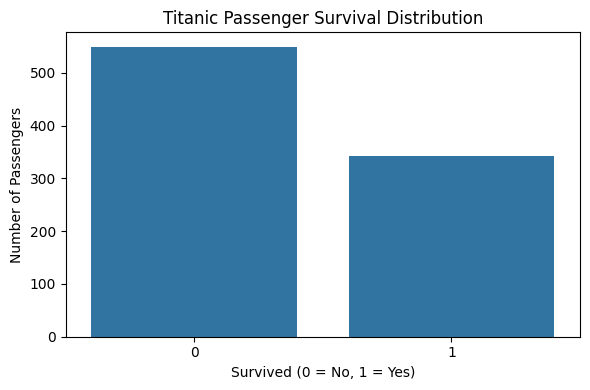

In [4]:
print("Survival counts:")
print(data["Survived"].value_counts().sort_index())

plt.figure(figsize=(6, 4))
sns.countplot(data=data, x="Survived")
plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

Survival rate by gender (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


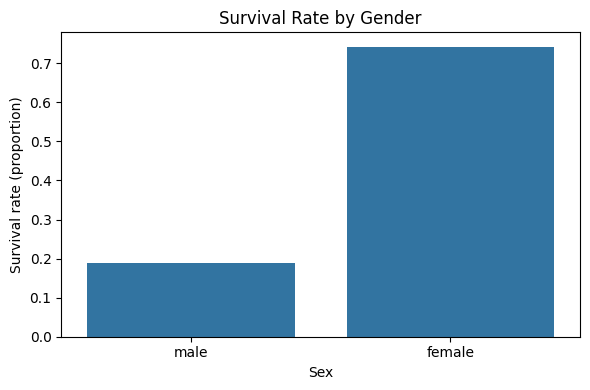

In [5]:
gender_survival = (
    data.groupby("Sex", observed=True)["Survived"].mean() * 100
)
print("Survival rate by gender (%):")
print(gender_survival.round(2))

plt.figure(figsize=(6, 4))
sns.barplot(data=data, x="Sex", y="Survived", errorbar=None)
plt.title("Survival Rate by Gender")
plt.ylabel("Survival rate (proportion)")
plt.tight_layout()
plt.show()

Survival rate by passenger class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


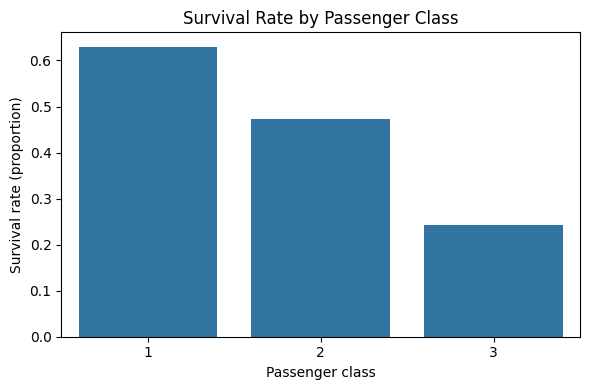

In [6]:
class_survival = (
    data.groupby("Pclass", observed=True)["Survived"].mean() * 100
)
print("Survival rate by passenger class (%):")
print(class_survival.round(2))

plt.figure(figsize=(6, 4))
sns.barplot(data=data, x="Pclass", y="Survived", errorbar=None)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger class")
plt.ylabel("Survival rate (proportion)")
plt.tight_layout()
plt.show()

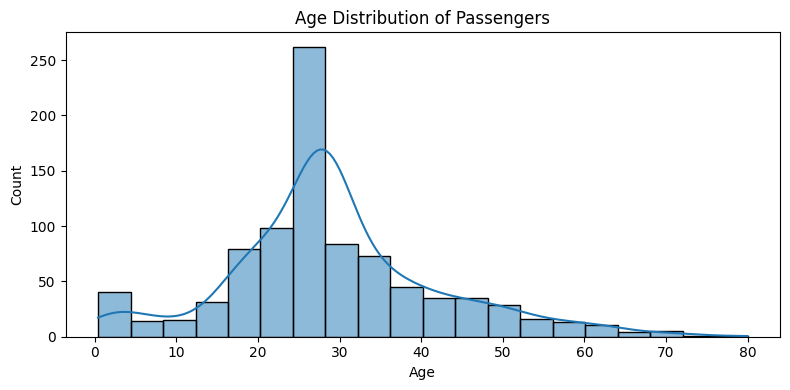

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(data=data, x="Age", bins=20, kde=True)
plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.tight_layout()
plt.show()

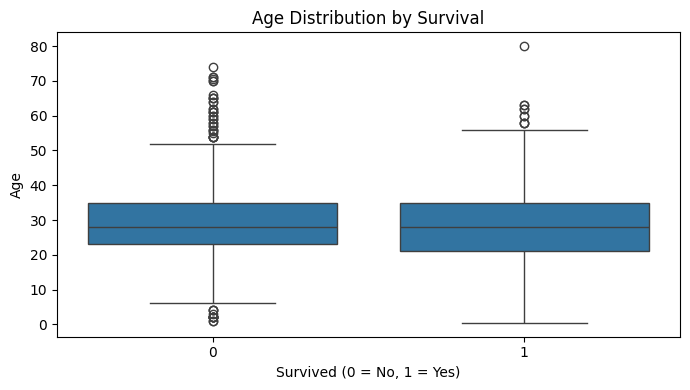

In [8]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=data, x="Survived", y="Age")
plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

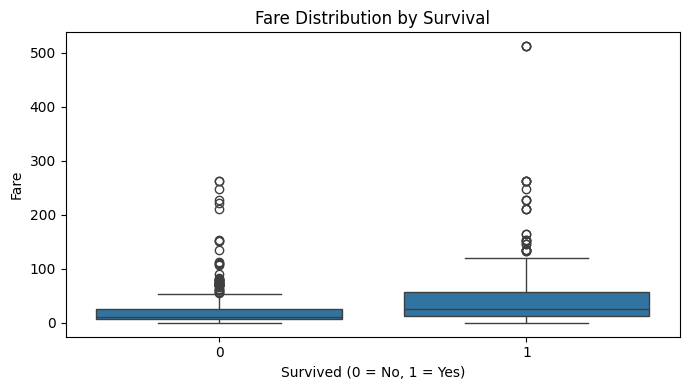

In [9]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=data, x="Survived", y="Fare")
plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

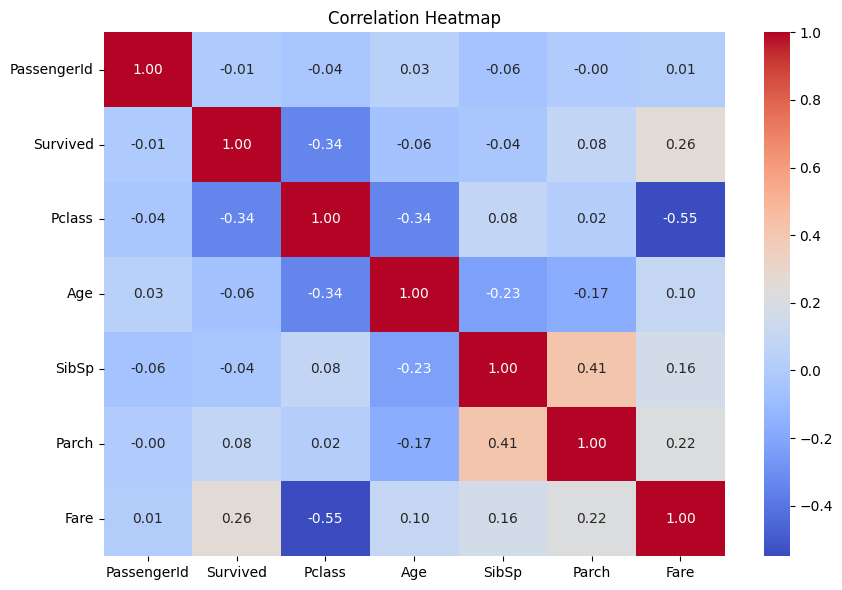

In [10]:
numeric_data = data.select_dtypes(include=np.number)

plt.figure(figsize=(9, 6))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 8. Key Findings and Insights

1. **Survival distribution:** The target distribution shows the relative numbers of survivors and non-survivors. This helps assess class balance.

2. **Gender and survival:** The survival-rate comparison by gender helps identify whether survival outcomes differed between male and female passengers.

3. **Passenger class:** Survival rates across passenger classes help examine the relationship between ticket class and survival.

4. **Age:** Age distributions and boxplots help identify differences between survivors and non-survivors.

5. **Fare:** Comparing fare distributions by survival helps examine whether fare values were associated with different survival outcomes.

6. **Feature relationships:** The correlation heatmap shows linear relationships between numerical variables. These relationships can inform feature selection, but correlation does not establish causation.

The actual values and visualizations above should be used to support these findings.

## 9. Machine Learning Model

Logistic Regression is used as a baseline classification model. The target is Survived, and the remaining selected passenger characteristics are input features.

PassengerId, Name, and Ticket are excluded because they are identifiers or high-cardinality fields that are not needed for this baseline.

In [11]:
# Exclude target and identifier/high-cardinality columns
excluded_columns = [
    "Survived", "PassengerId", "Name", "Ticket"
]

X = data.drop(
    columns=excluded_columns,
    errors="ignore"
)

y = data["Survived"]

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Split before fitting preprocessing or the model
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))
print("\nTraining survival distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting survival distribution:")
print(y_test.value_counts(normalize=True).round(3))

Numerical features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical features: ['Sex', 'Embarked']

Training records: 712
Testing records: 179

Training survival distribution:
Survived
0    0.617
1    0.383
Name: proportion, dtype: float64

Testing survival distribution:
Survived
0    0.615
1    0.385
Name: proportion, dtype: float64


In [12]:
# Preprocess numerical and categorical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Build a complete model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
# Predict on unseen test records
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1 Score:  {f1:.3f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Evaluation Results
------------------------
Accuracy:  0.804
Precision: 0.793
Recall:    0.667
F1 Score:  0.724

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



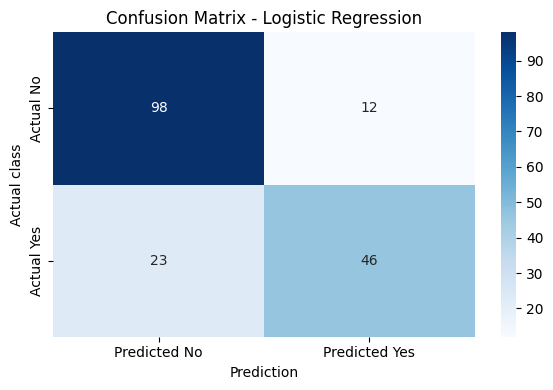

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Prediction")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()

## 10. Model Limitations

- Logistic Regression may not capture complex non-linear relationships.
- Model performance depends on the selected features and the quality of the data.
- A single train-test split may produce results that vary with other splits.
- Accuracy alone does not explain every type of prediction error.
- The dataset is historical and should not be treated as representative of all populations.
- The Cabin column was removed during earlier data preparation, so information from that column is unavailable.

## 11. Future Improvements

- Compare Logistic Regression with Decision Tree and Random Forest classifiers.
- Use cross-validation for a more stable performance estimate.
- Explore feature engineering and carefully selected additional variables.
- Compare precision, recall, F1 score, and other suitable metrics when choosing a model.

## 12. Conclusion

This project combined data preparation, exploratory data analysis, machine-learning model training, and evaluation into one workflow. Logistic Regression was trained to predict Titanic passenger survival and evaluated using accuracy, precision, recall, F1 score, and a confusion matrix.

The results provide a baseline for future experimentation. The model's performance and limitations should be considered before drawing conclusions about its predictive usefulness.

In [16]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [accuracy, precision, recall, f1]
})

display(results)

print("Project completed successfully.")

,Metric,Score
0,Accuracy,0.804469
1,Precision,0.793103
2,Recall,0.666667
3,F1 Score,0.724409


Project completed successfully.
